<a href="https://colab.research.google.com/github/danaz-py/pytorch_practice/blob/main/00_pytorch_fundamentals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# OO. Pytorch Fundamentals (DEC20, 2025)

https://www.learnpytorch.io/00_pytorch_fundamentals/

In [ ]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print(torch.__version__)

2.9.0+cu126


## Introduction to Tensors
https://docs.pytorch.org/docs/stable/tensors.html

Fundamental building block: represent data in a numerical way.

For example, you could represent an image as a tensor with shape `[3, 224, 224]` which would mean `[colour_channels, height, width]`, as in the image has 3 colour channels (red, green, blue), a height of 224 pixels and a width of 224 pixels.

A `torch.Tensor` is a multi-dimensional matrix containing elements of a single data type.
* Can be constructed as a list or sequence
*

In [ ]:
#scalar: a single number; zero dim tensor
scalar = torch.tensor(8)
scalar

tensor(8)

In [ ]:
print(scalar.ndim) #dimensions of the scalar
print(scalar.item()) #returns a regular python int

product = scalar.item() * 2 + 1 #see you can operations on it now
print(product)

0
8
17


In [ ]:
#vector: a single dimension tensor that can contain many numbers
vector = torch.tensor([8, 8])
vector

tensor([8, 8])

In [ ]:
print(vector.ndim) #number of brackets
print(vector.shape) #number of elements

1
torch.Size([2])


You can tell the number of dimensions a tensor in PyTorch has by the number of square brackets on the outside ([) and you tech only need to count one side.
* A scalar has no brackets
* A vector has 1 bracket

In [ ]:
#MATRIX: multiple vectors
MATRIX = torch.tensor([[1, 8], [6, 7]])
MATRIX

tensor([[1, 8],
        [6, 7]])

In [ ]:
#how many dimensions does it have
MATRIX.ndim

2

In [ ]:
print(MATRIX[0])
print(MATRIX[1])
#for some reason you need to use print if there are more than one

tensor([1, 8])
tensor([6, 7])


In [ ]:
MATRIX.shape
# 2 elements deep and 2 elements wide

torch.Size([2, 2])

In [ ]:
#TENSOR
TENSOR = torch.tensor([[[1, 2, 3], [6, 7, 8], [25, 26, 89]]])
TENSOR

tensor([[[ 1,  2,  3],
         [ 6,  7,  8],
         [25, 26, 89]]])

In [ ]:
TENSOR.ndim

3

In [ ]:
TENSOR.shape
#one 3 by 3 shape tensor

torch.Size([1, 3, 3])

The dimensions go outer to inner.

That means there's 1 dimension of 3 by 3.

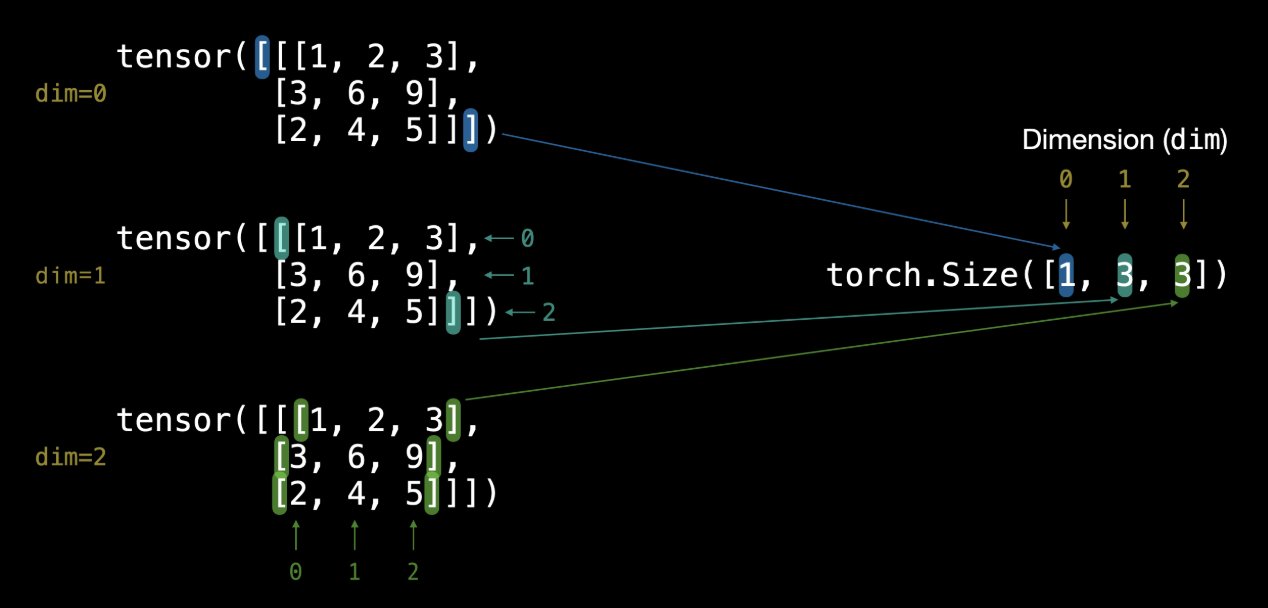

In [ ]:
TENSOR[0] #returns the first dimension, the whole outmost bracket

tensor([[ 1,  2,  3],
        [ 6,  7,  8],
        [25, 26, 89]])

## Random Tensors

Important b/c the way many neural networks learn is starting with tensors full of random numbers and then adjusting those rando numbers to better represent the data
1. Start with random numbers
2. look at data
3. Update random numbers
4. look at data
5. update random numbers

https://docs.pytorch.org/docs/stable/generated/torch.rand.html

In [ ]:
#Create a random tensor of size 3, 4
random_tensor = torch.rand(3, 4)
random_tensor

tensor([[0.4171, 0.5321, 0.7160, 0.6526],
        [0.1304, 0.1572, 0.0324, 0.2103],
        [0.9695, 0.0701, 0.1576, 0.5960]])

In [ ]:
random_tensor.ndim #2 brackets

2

In [ ]:
#Create a random tensor with similar shape to an image tensor
#1:44:00
random_image_size_tensor = torch.rand(size=(224, 224, 3))
                #height, width, color channels RGB
random_image_size_tensor.shape, random_image_size_tensor.ndim

(torch.Size([224, 224, 3]), 3)

## Zeroes and Ones

In [ ]:
zeros = torch.zeros(size=(3, 4))
zeros
#floats

tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])

In [ ]:
ones = torch.ones(size=(2, 3, 3))
#2 sets of 3x3 matrixes
ones
#floats

tensor([[[1., 1., 1.],
         [1., 1., 1.],
         [1., 1., 1.]],

        [[1., 1., 1.],
         [1., 1., 1.],
         [1., 1., 1.]]])

In [ ]:
ones.ndim

3

## Creating a range of tensors and tensors-like

https://docs.pytorch.org/docs/stable/generated/torch.arange.html

`torch.arange(start, end, step)`
* start = start of range (e.g. 0)
* end = end of range (e.g. 10)
* step = how many steps in between each value (e.g. 1)

In [ ]:
# Use torch.arange()
one_to_ten = torch.arange(1, 11)
one_to_ten

tensor([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

In [ ]:
eight_multiples = torch.arange(start=0, end=1000, step=8)
eight_multiples

tensor([  0,   8,  16,  24,  32,  40,  48,  56,  64,  72,  80,  88,  96, 104,
        112, 120, 128, 136, 144, 152, 160, 168, 176, 184, 192, 200, 208, 216,
        224, 232, 240, 248, 256, 264, 272, 280, 288, 296, 304, 312, 320, 328,
        336, 344, 352, 360, 368, 376, 384, 392, 400, 408, 416, 424, 432, 440,
        448, 456, 464, 472, 480, 488, 496, 504, 512, 520, 528, 536, 544, 552,
        560, 568, 576, 584, 592, 600, 608, 616, 624, 632, 640, 648, 656, 664,
        672, 680, 688, 696, 704, 712, 720, 728, 736, 744, 752, 760, 768, 776,
        784, 792, 800, 808, 816, 824, 832, 840, 848, 856, 864, 872, 880, 888,
        896, 904, 912, 920, 928, 936, 944, 952, 960, 968, 976, 984, 992])

In [ ]:
# Creaitng tensors like,
#filled with zeros or ones w the same shape as the input
ten_zeros = torch.zeros_like(one_to_ten)
ten_zeros

tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

## Tensor Datatypes

**Note:** Tensor datatypes if one of the 3 big errors you'll run into with PyTorch and deep learning
1. Tensors not right data type
2. Tensors not in right shape
3. Tensors not on right device


In [ ]:
# Float 32 tensor
float_32_tensor = torch.tensor([3.0, 6.0, 9.0],
                               dtype=None)
float_32_tensor.dtype #automatically a float32

torch.float32

In [ ]:
float_16_tensor_example = torch.tensor([3.0, 6.0, 9.0],
                               dtype=torch.float16)
float_16_tensor_example.dtype

torch.float16

Precision in comp sci:

In computer science, the precision of a numerical quantity is a measure of the detail in which the quantity is expressed. This is usually measured in bits, but sometimes in decimal digits. It is related to precision in mathematics, which describes the number of digits that are used to express a value.

In [ ]:
float_tensor = torch.tensor([3.0, 6.0, 9.0],
                            dtype=None, #what datatype is the center
                            device=None, #gpu vs cpu and whatnot
                            requires_grad=False) #track the gradients w/ this tensor?


When you run into issues in PyTorch, it's very often one to do with one of the three attributes above. So when the error messages show up, sing yourself a little song called "what, what, where":
* what shape are my tensors
* what datatype are they and where are they stored?
* what shape, what datatype, where where where


In [ ]:
float_16_tensor = float_32_tensor.type(torch.half) #float16
float_16_tensor

tensor([3., 6., 9.], dtype=torch.float16)

In [ ]:
float_16_tensor * float_32_tensor

tensor([ 9., 36., 81.])

In [ ]:
int_64_tensor = torch.tensor([3, 6, 9], dtype=torch.int64)
int_64_tensor

tensor([3, 6, 9])

In [ ]:
float_16_tensor * int_64_tensor #works!

tensor([ 9., 36., 81.], dtype=torch.float16)

In [ ]:
long_tensor = torch.tensor([3, 6, 9], dtype=torch.long)
long_tensor

tensor([3, 6, 9])

In [ ]:
float_16_tensor * long_tensor #works!

tensor([ 9., 36., 81.], dtype=torch.float16)

## Tensor Attributes
1. Tensors not right datatype - to get datatype from tensor use: `tensor.dtype`
3. Tensors not right shape - to get datatype from tensor use: `tensor.shape`
3. Tensors not right device - to get datatype from tensor use: `tensor.device`

In [ ]:
some_tensor = torch.rand(2, 3)
some_tensor

tensor([[0.0050, 0.7253, 0.7516],
        [0.6028, 0.6639, 0.1889]])

In [ ]:
some_tensor.size(), some_tensor.shape #practically same thing

(torch.Size([2, 3]), torch.Size([2, 3]))

In [ ]:
#finding details about some_tensor
print(some_tensor)
print(some_tensor.dtype)
print(some_tensor.shape)
print(some_tensor.device)

tensor([[0.0050, 0.7253, 0.7516],
        [0.6028, 0.6639, 0.1889]])
torch.float32
torch.Size([2, 3])
cpu


## Manipulating Tensor (tensor operations)

Tensor Operations include:
1. Addition
2. Subtraction
3. Multiplication
4. Division
5. Matrix Multiplication

In [ ]:
#ADDITION

tensor_operation = torch.tensor([1, 2, 3])
tensor_operation + 10

tensor([11, 12, 13])

In [ ]:
#no resassigning
tensor_operation

tensor([1, 2, 3])

In [ ]:
#MULTIPLCATION
tensor_operation * 10

tensor([10, 20, 30])

In [ ]:
#SUBTRCTING
tensor_operation - 10

tensor([-9, -8, -7])

In [ ]:
#PyTorch in-built functions
print(torch.mul(tensor_operation, 10)) #multplying by 10
print(torch.add(tensor_operation, 10)) #adding 10


tensor([10, 20, 30])
tensor([11, 12, 13])


## MATRIX MULTIPLICATION

https://www.mathsisfun.com/algebra/matrix-multiplying.html

Two main ways:
1. Element-wise multiplcation (by a scalar) `tensor * tensor`
2. Matrix Multiplication `tensor.matmul(tensor)`

A "Dot Product" is multiplying matching numbers then summing them up

In [ ]:
# Element wise multiplicaiton
print(tensor_operation, "*", tensor_operation)
print(f"Equals: {tensor_operation * tensor_operation}")

tensor([1, 2, 3]) * tensor([1, 2, 3])
Equals: tensor([1, 4, 9])


In [ ]:
# Matrix multiplcation
torch.matmul(tensor_operation, tensor_operation) #matmul stands for matrix multiplication
#You add them all together!

tensor(14)

In [ ]:
tensor_operation

tensor([1, 2, 3])

In [ ]:
# Matrix Multiplcation by hand
1 * 1 + 2 * 2 + 3 * 3

14

In [ ]:
# Matrix multiplication with a for loop
%%time
#time difference with the command vs for loop

value = 0
for i in range(len(tensor_operation)): #for each element in the length of our tensor
  value += tensor_operation[i] * tensor_operation[i]

CPU times: user 582 µs, sys: 0 ns, total: 582 µs
Wall time: 605 µs


In [ ]:
%%time
torch.matmul(tensor_operation, tensor_operation)
#its 10x quicker!

CPU times: user 51 µs, sys: 9 µs, total: 60 µs
Wall time: 73 µs


tensor(14)

### Neural networks are full of matrix multiplications and dot products
The `torch.nn.Linear()` module also known as a feed-forward layer or fully connected layer, implements a matrix multiplication between an input x and a weights matrix A.

y = x • A^T + b

* x is the input to the layer (deep learning is a stack of layers like torch.nn.Linear() and others on top of each other).
* A is the weights matrix created by the layer, this starts out as random numbers that get adjusted as a neural network learns to better represent patterns in the data (notice the "T", that's because the weights matrix gets transposed).
  * Note: You might also often see W or another letter like X used to showcase the weights matrix.
* b is the bias term used to slightly offset the weights and inputs.
* y is the output (a manipulation of the input in the hopes to discover patterns in it).

### 2 Main Errors in Matrix Multiplication

1. The **inner dimensions** must match:
    - `(3, 2) @ (3, 2)` wont work
    - `(2, 3) @ (3, 2)` will work

2. The resulting matrix as the shape of the **outer dimensionsn**
    - `(2, 3) @ (3, 2)` will result in a shape of 2x2
    - '(8, 25)` @ `(25, 456)` will result in a shape of 8x456

In [ ]:
torch.matmul(torch.rand(3,2), torch.rand(3, 2))

RuntimeError: mat1 and mat2 shapes cannot be multiplied (3x2 and 3x2)

In [ ]:
torch.matmul(torch.rand(2,3), torch.rand(3, 2))

tensor([[0.5898, 0.3141],
        [0.7312, 0.2502]])

In [ ]:
torch.matmul(torch.rand(8, 25), torch.rand(25, 456)).shape

torch.Size([8, 456])

http://matrixmultiplication.xyz/

pratice matrix multiplication

## Shape Errors

In [ ]:
#shapes for matrix mult
tensor_A = torch.tensor([[1, 2],
                         [3, 4],
                         [5, 6]])
tensor_B = torch.tensor([[7, 10],
                         [8, 11],
                         [9, 12]])

#torch.matmul(tensor_A, tensor_B)


In [ ]:
tensor_A.shape, tensor_B.shape

(torch.Size([3, 2]), torch.Size([3, 2]))

A **transpose** switches the axes or dimensions of a given tensor

3x2 --> 2x3

* `torch.transpose(input, dim0, dim1)` - where input is the desired tensor to transpose and dim0 and dim1 are the dimensions to be swapped.
* `tensor.T` - where tensor is the desired tensor to transpose.

In [ ]:
tensor_B, tensor_B.shape

(tensor([[ 7, 10],
         [ 8, 11],
         [ 9, 12]]),
 torch.Size([3, 2]))

In [ ]:
tensor_B.T, tensor_B.T.shape

(tensor([[ 7,  8,  9],
         [10, 11, 12]]),
 torch.Size([2, 3]))

In [ ]:
#Works when tensor_B is transposed because it fits the 2 rules
torch.matmul(tensor_A, tensor_B.T).shape

torch.Size([3, 3])

## Tensor Aggregation
Finding the min, max, mean, sum etc

In [ ]:
x = torch.arange(0, 100, 10)
#start, end, step
x

tensor([ 0, 10, 20, 30, 40, 50, 60, 70, 80, 90])

In [ ]:
x.dtype

torch.int64

In [ ]:
torch.min(x), x.min()

(tensor(0), tensor(0))

In [ ]:
torch.max(x), x.max()

(tensor(90), tensor(90))

In [ ]:
#torch.mean() functions requires a float32 datatype to work
torch.mean(x.type(torch.float32)), x.type(torch.float32).mean() #cant be a int64 so we change it to float32

(tensor(45.), tensor(45.))

In [ ]:
torch.sum(x), x.sum()

(tensor(450), tensor(450))

### Finding Positional Min and Max

In [ ]:
x

tensor([ 0, 10, 20, 30, 40, 50, 60, 70, 80, 90])

In [ ]:
#Find the posiiton in the tensor that has the min value with argmin()
# -> returns index posiiton of target tensor
x.argmin()
#gives you the index

tensor(0)

In [ ]:
x[0]

tensor(0)

In [ ]:
#Find the posiiton in the tensor that has the max value with argmax()
# -> returns index posiiton of target tensor
x.argmax()

tensor(9)

In [ ]:
x[9]

tensor(90)

## Reshaping, Viewing, Stacking

* Reshaping - reshapes an input tensor to a defined shape
* View - Return a view of an input tensor of certain shape but keey the same memory as the original tensor
* Stacking - combine multiple tensors on top of each other (vstack) or side by side (hstack)

https://docs.pytorch.org/docs/stable/generated/torch.stack.html

In [ ]:
y = torch.arange(1., 10.)
y, y.shape

(tensor([1., 2., 3., 4., 5., 6., 7., 8., 9.]), torch.Size([9]))

In [ ]:
#Add an extra dimension
#must be compatible
y_reshaped = y.reshape(3, 3)
y_reshaped, y_reshaped.shape

(tensor([[1., 2., 3.],
         [4., 5., 6.],
         [7., 8., 9.]]),
 torch.Size([3, 3]))

In [ ]:
#Change the view
z = y.view(1, 9)
z, z.shape

(tensor([[1., 2., 3., 4., 5., 6., 7., 8., 9.]]), torch.Size([1, 9]))

In [ ]:
# Changing z changes x (b/c a iew of a tensor shared the same memory as the original input)
z[:, 0] = 5
z, y

(tensor([[5., 2., 3., 4., 5., 6., 7., 8., 9.]]),
 tensor([5., 2., 3., 4., 5., 6., 7., 8., 9.]))

In [ ]:
#Stack tensors on top of eachother
y_stacked = torch.stack([y, y, y, y], dim=0) #dimension, play around
y_stacked

tensor([[5., 2., 3., 4., 5., 6., 7., 8., 9.],
        [5., 2., 3., 4., 5., 6., 7., 8., 9.],
        [5., 2., 3., 4., 5., 6., 7., 8., 9.],
        [5., 2., 3., 4., 5., 6., 7., 8., 9.]])

## Squeezing and Unsqueezing

* Squeeze - remove all 1 dimensions from a tensor
* Unsqueeze - add a 1 dimension to a target tensor
* Permute - return a view of te input with dimensions permuted (swapped) a certain way

https://docs.pytorch.org/docs/stable/generated/torch.squeeze.html
https://docs.pytorch.org/docs/stable/generated/torch.permute.html

because deep learning models (neural networks) are all about manipulating tensors in some way. And because of the rules of matrix multiplication, if you've got shape mismatches, you'll run into errors. These methods help you make sure the right elements of your tensors are mixing with the right elements of other tensors.

In [ ]:
y_reshaped = y_reshaped.reshape(1, 9)

In [ ]:
#torch.squeeze() - removes all single dimensions
print(f"Previous tensor: {y_reshaped}")
print(f"Previous shape: {y_reshaped.shape}")

#Remove extra dimensions from y_reshaped
y_squeezed = y_reshaped.squeeze()
print(f"\nNew Tensor: {y_squeezed}")
print(f"New Shape: {y_squeezed.shape}")


Previous tensor: tensor([[5., 2., 3., 4., 5., 6., 7., 8., 9.]])
Previous shape: torch.Size([1, 9])

New Tensor: tensor([5., 2., 3., 4., 5., 6., 7., 8., 9.])
New Shape: torch.Size([9])


In [ ]:
y_reshaped

tensor([[5., 2., 3., 4., 5., 6., 7., 8., 9.]])

In [ ]:
y_reshaped.shape

torch.Size([1, 9])

In [ ]:
y_reshaped.squeeze()
#look at the brackets

tensor([5., 2., 3., 4., 5., 6., 7., 8., 9.])

In [ ]:
y_reshaped.squeeze().shape

torch.Size([9])

In [ ]:
# torch.unsqueeze() - adds a single dimension to a target tensor at a specific dim
print(f"Previous target: {y_squeezed}")
print(f"Previous shape: {y_squeezed.shape}")

#Add extra dimension
y_unsqueezed = y_squeezed.unsqueeze(dim=0)
print(f"\nNew Tensor: {y_unsqueezed}")
print(f"New Shape: {y_unsqueezed.shape}")

Previous target: tensor([5., 2., 3., 4., 5., 6., 7., 8., 9.])
Previous shape: torch.Size([9])

New Tensor: tensor([[5., 2., 3., 4., 5., 6., 7., 8., 9.]])
New Shape: torch.Size([1, 9])


In [ ]:
# torch.permute - rearranges the dimensions of the target tensor in a specified order
x_original = torch.rand(size=(224, 224, 3)) # [height, width, color channel] aka [0, 1, 2]

#Permute the original tensor to rearrange the axis (or dim) order
x_permuted = x_original.permute(2, 0, 1) # [color channel, height, width] aka [2, 0, 1]

print(f"Previous shape: {x_original.shape}")
print(f"New shape: {x_permuted.shape}")

Previous shape: torch.Size([224, 224, 3])
New shape: torch.Size([3, 224, 224])


## Indexing: selecting data from tensors

Indexing with PyTorch is similar to indexing with NumPy

In [ ]:
r = torch.arange(1, 10).reshape(1, 3, 3)
r, r.shape

(tensor([[[1, 2, 3],
          [4, 5, 6],
          [7, 8, 9]]]),
 torch.Size([1, 3, 3]))

In [ ]:
#index on new tensor
r[0] #first bracket

tensor([[1, 2, 3],
        [4, 5, 6],
        [7, 8, 9]])

In [ ]:
r[0][0] #first bracket, the first row of the bracket

tensor([1, 2, 3])

In [ ]:
r[0][0][0] #first bracket, first row, first number of that row

tensor(1)

In [ ]:
r[1][1][1] #second bracket (DOESNT EXIST!), second row, second number in that row

IndexError: index 1 is out of bounds for dimension 0 with size 1

In [ ]:
#You can also use ":" to select all of a target dimension
r[:, 0] #all values of first dimension
## Get all values of 0th dimension and the 0 index of 1st dimension

tensor([[1, 2, 3]])

In [ ]:
#get all values of 0th and 1st dimension but only index one of second dimension
r[:, :, 1]

tensor([[2, 5, 8]])

In [ ]:
#get all values of 0 dimension but only the 1 index of the 1st and 2nd dimension
if r[:, 1, 1] == r[0][1][1]:
  print(r[:, 1, 1])
  print(r[0][1][1])


tensor([5])
tensor(5)


In [ ]:
#get index 0 of the 0th and 1st dimension and all values of 2nd dimension
r[0, 0, :]

tensor([1, 2, 3])

In [ ]:
#index on r to return 9
r[0][2][2]

tensor(9)

In [ ]:
#index on r to return 3, 6, 9
r[:, :, 2]


tensor([[3, 6, 9]])

## PyTorch and NumPy
* converting numpy to torch
`torch.from_numpay(ndarray)`
* converting torch to numpy
`torch.Tensor.numpy()`

https://docs.pytorch.org/tutorials/beginner/examples_tensor/polynomial_numpy.html

In [ ]:
#NumPy array to tensor
array = np.arange(1.0, 8.0)
tensor_array = torch.from_numpy(array)
#when converting from numpy -> pytorch, pytorc reflects numpy's default datatype of float 64
array, tensor_array

(array([1., 2., 3., 4., 5., 6., 7.]),
 tensor([1., 2., 3., 4., 5., 6., 7.], dtype=torch.float64))

In [ ]:
# Change the value of array, what will this do to tensor?
array = array + 1
array, tensor_array
#nothing

(array([2., 3., 4., 5., 6., 7., 8.]),
 tensor([1., 2., 3., 4., 5., 6., 7.], dtype=torch.float64))

In [ ]:
#Tensor to NumPy array
array_tensor = torch.ones(8)
numpy_tensor = array_tensor.numpy()
array_tensor, numpy_tensor

(tensor([1., 1., 1., 1., 1., 1., 1., 1.]),
 array([1., 1., 1., 1., 1., 1., 1., 1.], dtype=float32))

In [ ]:
#Change the tensor, what will do this to the array?
array_tensor = array_tensor + 1
array_tensor, numpy_tensor
#nothing

(tensor([2., 2., 2., 2., 2., 2., 2., 2.]),
 array([1., 1., 1., 1., 1., 1., 1., 1.], dtype=float32))

## PyTorch Reproducibility
Trying to take random out of random

In short, how a neural network learns:
1. Start with random numbers
2. tensor operations
3. update random numbers to make them better representations of the data
4. repeat

to reduce randomness in neural networks and PyTorch comes the concept of a **random seed**.

Essentially this random seed "flavours" the randomness

https://docs.pytorch.org/docs/stable/notes/randomness.html

In [ ]:
torch.rand(3, 3)

tensor([[0.4419, 0.2990, 0.5981],
        [0.6625, 0.9106, 0.9342],
        [0.0585, 0.3434, 0.2740]])

In [ ]:
random_tensor_A = torch.rand(3, 4)
random_tensor_B = torch.rand(3, 4)

print(random_tensor_A)
print(random_tensor_B)
print(random_tensor_A == random_tensor_B)

tensor([[0.8229, 0.9729, 0.2854, 0.9275],
        [0.1765, 0.3284, 0.7159, 0.0711],
        [0.1940, 0.6685, 0.9846, 0.5122]])
tensor([[0.6489, 0.3410, 0.7614, 0.5097],
        [0.3074, 0.3614, 0.8052, 0.9183],
        [0.7364, 0.6045, 0.4325, 0.8011]])
tensor([[False, False, False, False],
        [False, False, False, False],
        [False, False, False, False]])


In [ ]:
#random but reproducible tensors

#set the random seed
RANDOM_SEED = 3.14159

torch.manual_seed(RANDOM_SEED) #works for only 1 block of code
random_tensor_C = torch.rand(3, 4)

torch.manual_seed(RANDOM_SEED)
random_tensor_D = torch.rand(3, 4)

print(random_tensor_C)
print(random_tensor_D)
print(random_tensor_C == random_tensor_D)

tensor([[0.0043, 0.1056, 0.2858, 0.0270],
        [0.4716, 0.0601, 0.7719, 0.7437],
        [0.5944, 0.8879, 0.4510, 0.7995]])
tensor([[0.0043, 0.1056, 0.2858, 0.0270],
        [0.4716, 0.0601, 0.7719, 0.7437],
        [0.5944, 0.8879, 0.4510, 0.7995]])
tensor([[True, True, True, True],
        [True, True, True, True],
        [True, True, True, True]])


## Running tensors and PyTorch objects on GPUs

GPUs = faster computation on numbers

1. Use Google Colab
2. Use your own GPU
3. use cloud computing


In [ ]:
torch.cuda.is_available()

True

In [ ]:
#Create a tensor (default on CPU)
tensor_CPU = torch.tensor([1, 2, 3], device="cpu")

print(tensor_CPU, tensor_CPU.device)

tensor([1, 2, 3]) cpu


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [ ]:
#Move tensor to GPU (if available)
tensor_on_gpu = tensor_CPU.to(device)
tensor_on_gpu

tensor([1, 2, 3], device='cuda:0')